In [1]:
import os
import time
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from pathlib import Path
from PIL import Image

from torchvision import models, transforms
from torchvision.models import ResNet18_Weights
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cpu")

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data"
IMAGE_DIR = DATA_DIR / "Images"
SPLIT_DIR = DATA_DIR / "splits"
MODEL_DIR = PROJECT_DIR / "models"
RESULT_DIR = PROJECT_DIR / "results"

MODEL_DIR.mkdir(exist_ok=True)
RESULT_DIR.mkdir(exist_ok=True)

print("Device:", DEVICE)
print("Setup completed!")

Device: cpu
Setup completed!


In [2]:
train_df = pd.read_csv(SPLIT_DIR / "train.csv")
val_df = pd.read_csv(SPLIT_DIR / "validation.csv")
test_df = pd.read_csv(SPLIT_DIR / "test.csv")

df = pd.read_csv(DATA_DIR / "FETAL_PLANES_DB_data.csv", sep=";")
df.columns = df.columns.str.strip()

class_names = sorted(df["Plane"].unique())
class_to_idx = {
    name: idx for idx, name in enumerate(class_names)
}

num_classes = len(class_names)

print("Classes:", class_names)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

Classes: ['Fetal abdomen', 'Fetal brain', 'Fetal femur', 'Fetal thorax', 'Maternal cervix', 'Other']
Training images: 6217
Validation images: 912
Test images: 5271


In [3]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

print("Transforms created!")

Transforms created!


In [4]:
class FetalUltrasoundDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image_path = self.image_dir / f"{row['Image_name']}.png"
        image = Image.open(image_path).convert("RGB")

        label = class_to_idx[row["Plane"]]

        if self.transform:
            image = self.transform(image)

        return image, label


train_dataset = FetalUltrasoundDataset(
    train_df, IMAGE_DIR, train_transform
)

val_dataset = FetalUltrasoundDataset(
    val_df, IMAGE_DIR, eval_transform
)

test_dataset = FetalUltrasoundDataset(
    test_df, IMAGE_DIR, eval_transform
)

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 6217
Validation: 912
Test: 5271


In [5]:
model = models.resnet18(
    weights=ResNet18_Weights.DEFAULT
)

# All layers trainable
for param in model.parameters():
    param.requires_grad = True

# Replace final classifier
model.fc = nn.Linear(
    model.fc.in_features,
    num_classes
)

model = model.to(DEVICE)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel() for p in model.parameters()
)

print("Full fine-tuning model initialized!")
print("Trainable parameters:", trainable_params)
print("Total parameters:", total_params)
print("All layers are trainable:", trainable_params == total_params)

Full fine-tuning model initialized!
Trainable parameters: 11179590
Total parameters: 11179590
All layers are trainable: True


In [6]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    [
        {
            "params": [
                p for name, p in model.named_parameters()
                if not name.startswith("fc.")
            ],
            "lr": 1e-5
        },
        {
            "params": model.fc.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=1
)

EPOCHS = 3

print("Loss: Standard CrossEntropyLoss")
print("Optimizer: Adam")
print("Backbone LR: 1e-5")
print("Classifier LR: 1e-4")
print("Epochs:", EPOCHS)

Loss: Standard CrossEntropyLoss
Optimizer: Adam
Backbone LR: 1e-5
Classifier LR: 1e-4
Epochs: 3


In [7]:
history = []

best_val_accuracy = 0.0

MODEL_PATH = MODEL_DIR / "resnet18_full_finetuned_best.pth"

for epoch in range(EPOCHS):

    start_time = time.time()

    # Training
    model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    # Validation
    model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_accuracy = val_correct / val_total

    scheduler.step(val_loss)

    epoch_time = (time.time() - start_time) / 60

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy,
        "time_minutes": epoch_time
    })

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save({
            "model_state_dict": copy.deepcopy(model.state_dict()),
            "class_names": class_names,
            "class_to_idx": class_to_idx,
            "best_val_accuracy": best_val_accuracy
        }, MODEL_PATH)

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Time: {epoch_time:.2f} minutes")

print("\nFull fine-tuning completed!")
print("Best validation accuracy:", best_val_accuracy)
print("Model saved:", MODEL_PATH)


Epoch 1/3
Train Loss: 0.6223
Train Accuracy: 0.7997
Validation Loss: 0.3176
Validation Accuracy: 0.9024
Time: 17.85 minutes

Epoch 2/3
Train Loss: 0.2641
Train Accuracy: 0.9131
Validation Loss: 0.2236
Validation Accuracy: 0.9320
Time: 14.97 minutes

Epoch 3/3
Train Loss: 0.1959
Train Accuracy: 0.9328
Validation Loss: 0.1982
Validation Accuracy: 0.9397
Time: 15.90 minutes

Full fine-tuning completed!
Best validation accuracy: 0.9396929824561403
Model saved: C:\B.tech\Project\Fetal_Ultrasound_Project\models\resnet18_full_finetuned_best.pth


,epoch,train_loss,val_loss,train_accuracy,val_accuracy,time_minutes
0,1,0.622329,0.317609,0.799743,0.902412,17.851885
1,2,0.264130,0.223614,0.913141,0.932018,14.965518
2,3,0.195887,0.198231,0.932765,0.939693,15.898098


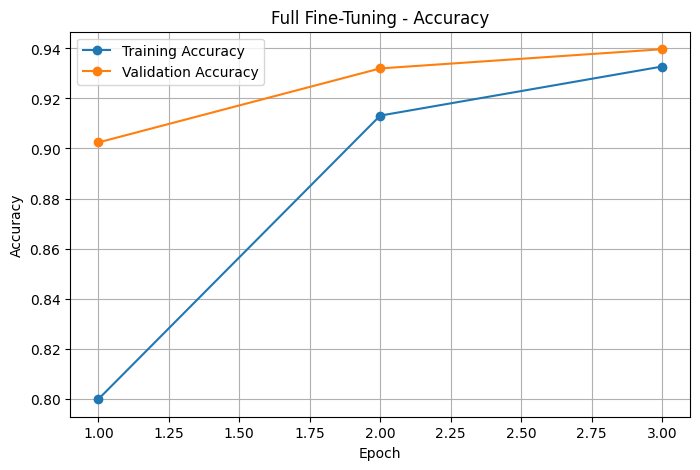

In [9]:
history_df = pd.DataFrame(history)

history_df.to_csv(
    RESULT_DIR / "full_finetuning_history.csv",
    index=False
)

display(history_df)

plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Full Fine-Tuning - Accuracy")
plt.legend()
plt.grid(True)

plt.savefig(
    RESULT_DIR / "full_finetuning_accuracy.png",
    dpi=300
)

plt.show()

In [10]:
checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.numpy())
        all_labels.extend(labels.numpy())

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

print(f"Full Fine-Tuning Test Accuracy: {test_accuracy * 100:.2f}%")
print("Total predictions:", len(all_predictions))

Full Fine-Tuning Test Accuracy: 92.51%
Total predictions: 5271


In [11]:
report = classification_report(
    all_labels,
    all_predictions,
    labels=list(range(num_classes)),
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(report)

report_dict = classification_report(
    all_labels,
    all_predictions,
    labels=list(range(num_classes)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report_dict).transpose().to_csv(
    RESULT_DIR / "full_finetuning_classification_report.csv"
)

                 precision    recall  f1-score   support

  Fetal abdomen     0.8325    0.9162    0.8723       358
    Fetal brain     0.9905    0.9912    0.9908      1472
    Fetal femur     0.8396    0.8989    0.8682       524
   Fetal thorax     0.8645    0.9182    0.8905       660
Maternal cervix     0.9954    0.9969    0.9961       645
          Other     0.9151    0.8493    0.8810      1612

       accuracy                         0.9251      5271
      macro avg     0.9062    0.9284    0.9165      5271
   weighted avg     0.9265    0.9251    0.9251      5271



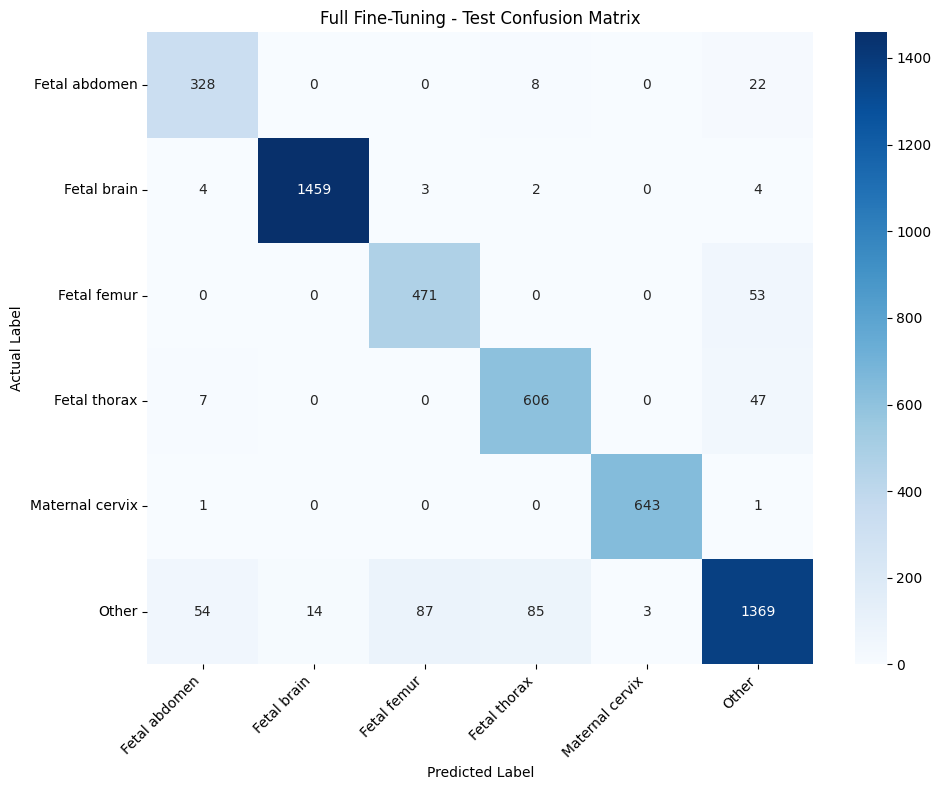

In [12]:
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(num_classes))
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Full Fine-Tuning - Test Confusion Matrix")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    RESULT_DIR / "full_finetuning_confusion_matrix.png",
    dpi=300
)

plt.show()

In [13]:
full_finetune_predictions = pd.DataFrame({
    "Actual": [class_names[i] for i in all_labels],
    "Predicted": [class_names[i] for i in all_predictions]
})

full_finetune_predictions.to_csv(
    RESULT_DIR / "full_finetuning_test_predictions.csv",
    index=False
)

print("Full fine-tuning predictions saved!")

Full fine-tuning predictions saved!


In [14]:
# Load previous experiment results
baseline_acc = 93.7204
weighted_partial_acc = 89.3379
unweighted_partial_acc = 89.96

# Current full fine-tuning result
full_finetuning_acc = test_accuracy * 100

comparison = pd.DataFrame({
    "Experiment": [
        "Baseline ResNet18",
        "Partial Fine-tuning + Class Weights",
        "Partial Fine-tuning without Weights",
        "Full Fine-tuning ResNet18"
    ],
    "Test Accuracy (%)": [
        baseline_acc,
        weighted_partial_acc,
        unweighted_partial_acc,
        full_finetuning_acc
    ]
})

comparison = comparison.sort_values(
    by="Test Accuracy (%)",
    ascending=False
).reset_index(drop=True)

display(comparison)

comparison.to_csv(
    RESULT_DIR / "all_experiments_comparison.csv",
    index=False
)

print("Best experiment:", comparison.iloc[0]["Experiment"])
print(
    "Best test accuracy:",
    round(comparison.iloc[0]["Test Accuracy (%)"], 2),
    "%"
)

,Experiment,Test Accuracy (%)
0,Baseline ResNet18,93.720400
1,Full Fine-tuning ResNet18,92.506166
2,Partial Fine-tuning without Weights,89.960000
3,Partial Fine-tuning + Class Weights,89.337900


Best experiment: Baseline ResNet18
Best test accuracy: 93.72 %


In [15]:
for folder, subfolders, files in os.walk(PROJECT_DIR):
    subfolders[:] = [
        s for s in subfolders
        if s not in [".ipynb_checkpoints", "__pycache__"]
    ]

    level = len(Path(folder).relative_to(PROJECT_DIR).parts)

    if level > 2:
        continue

    indent = "    " * level

    print(f"{indent}{Path(folder).name}/")

    for file in files:
        print(f"{indent}    {file}")

Fetal_Ultrasound_Project/
    data/
        FETAL_PLANES_DB_data.csv
        FETAL_PLANES_DB_data.xlsx
        README.md
        Images/
            Patient00001_Plane1_10_of_15.png
            Patient00001_Plane1_11_of_15.png
            Patient00001_Plane1_12_of_15.png
            Patient00001_Plane1_13_of_15.png
            Patient00001_Plane1_14_of_15.png
            Patient00001_Plane1_15_of_15.png
            Patient00001_Plane1_1_of_15.png
            Patient00001_Plane1_2_of_15.png
            Patient00001_Plane1_3_of_15.png
            Patient00001_Plane1_4_of_15.png
            Patient00001_Plane1_5_of_15.png
            Patient00001_Plane1_6_of_15.png
            Patient00001_Plane1_7_of_15.png
            Patient00001_Plane1_8_of_15.png
            Patient00001_Plane1_9_of_15.png
            Patient00002_Plane1_10_of_20.png
            Patient00002_Plane1_11_of_20.png
            Patient00002_Plane1_12_of_20.png
            Patient00002_Plane1_13_of_20.png
            Patie